# 01 · Simulación de los datos

**Artículo:** Mihaljević, H. & Santamaría, L. (2021). *Disambiguation of author entities in ADS using supervised learning and graph theory methods*. Scientometrics 126, 3893–3917.

Este notebook cubre los pasos 3 y 4 de la guía:

1. **Caracterizar** los datos que reporta el artículo (Tablas 1, 3, 7 y 9).
2. **Simular** un conjunto de autorías que conserve esas características y **declarar los supuestos** de todo lo que el artículo no reporta.
3. Verificar que la simulación reproduce las cifras objetivo y hacer un análisis exploratorio de las variables de pares.

Toda la lógica está en `src/simulation.py`, `src/names.py` y `src/features.py`; aquí solo se ejecuta y se inspecciona.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C, features as F, plots as PL, simulation as S

PL.set_style()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

## 1. Lo que reporta el artículo

* **Población:** registros de la base *Astronomy* de ADS (snapshot de marzo de 2018): 924.329 documentos y 3.667.321 autorías (≈ 4 autores por artículo).
* **Bloques:** apellido + primera inicial, sin diacríticos y en minúsculas (`sorensen.l`). 166.545 bloques con ≥ 2 autorías; tamaño medio 21 con desviación ≈ 50; el mayor es `wang.j` con 2.170 autorías.
* **Unidad de análisis:** la *autoría* (par publicación–persona). **Unidad de modelado:** el *par de autorías* dentro de un bloque.
* **Variable objetivo:** `y = 1` si las dos autorías son de la misma persona.
* **Muestra etiquetada:** 137 bloques; 98 para entrenar y 39 para evaluar (6 de los 10 bloques más grandes + 33 aleatorios).

In [2]:
art3 = pd.DataFrame(C.ARTICLE_TABLE3).T
art3

,blocks,authorships,labeled,mean_block,median_block,profiles_mean,profiles_median,pairs,pct_class1
train,98.0,2487.0,2318.0,23.7,5.0,2.6,1.0,204299.0,64.9
test_all,39.0,11567.0,9545.0,244.7,35.0,14.4,2.0,5503931.0,47.0
test_large,6.0,10006.0,7996.0,1332.7,1304.0,79.2,80.5,5423970.0,46.5
test_random,33.0,1561.0,1549.0,46.9,24.0,2.6,1.0,79961.0,77.4


**Cobertura de los campos (Tabla 1):** autor, año, revista y coautores 100 %; título 99,9 %; resumen 78,7 %; afiliación 78 %; palabras clave 65,3 %.

**Lo que el artículo NO reporta** y hubo que suponer: la distribución del número de autorías por autor, cuántos nombres aparecen abreviados, cómo se escriben los nombres asiáticos, la movilidad institucional, el tamaño de los grupos de coautores, el vocabulario de los textos, etc. Cada supuesto queda registrado en la tabla de la sección 3.

## 2. Simulación

Modelo generativo (ver docstring de `src/simulation.py`):

* **Bloques:** los 6 bloques grandes y los 33 aleatorios de prueba usan los **nombres, tamaños y número de perfiles exactos** de las Tablas 7 y 9 (los grandes, escalados a la mitad). Los 98 de entrenamiento siguen una lognormal con la mediana (5) y el total (2.487) de la Tabla 3.
* **Productividad:** las autorías de un bloque se reparten entre sus autores con una ley de Zipf. El exponente se **calibra** para reproducir el % de pares de clase 1 de la Tabla 3 (64,9 / 77,4 / 46,5 %).
* **Autores:** cada uno tiene nombre canónico, instituciones (con posible cambio a mitad de carrera), temas, frases y acrónimos propios, grupo de coautores, revistas preferidas y años de actividad.
* **Autorías:** heredan los atributos del autor con ruido; el nombre aparece abreviado o completo; los campos faltan según la Tabla 1.

In [3]:
df, specs = S.simulate(C.SEED)
print(f"{len(df):,} autorías · {df.block.nunique()} bloques · {df.author_id.nunique()} autores reales")
df.to_csv(C.DATA / "simulated_authorships.csv", index=False)
specs.to_csv(C.DATA / "block_specs.csv", index=False)

8,034 autorías · 137 bloques · 580 autores reales


Ejemplo de autorías simuladas del bloque `chen.y` (las columnas `latent_*` y `u_*` son internas de la simulación: nunca entran al modelo).

In [4]:
cols = ["name", "affiliation", "year", "journal", "coauthors", "keywords", "author_id"]
df[df.block == "chen.y"][cols].head(8)

,name,affiliation,year,journal,coauthors,keywords,author_id
1473,"Chen, Yan-Zhong",,2007,Monthly Notices of the Royal Astronomical Society,bryant.h; suzuki.f; allen.l,,chen.y#000
1474,"Chen, Ying-Ping","Department of Physics, Institute of Astronomy, Pohang, Pohang, South Korea",1987,Icarus,leroy.k; kuznetsov.k; cox.t; smirnov.c,cosmology: vogohic; stars: beva; gravitational waves: hupom; cosmology: bigu...,chen.y#005
1475,"Chen, Y. L.",,2005,Nature,king.c; marino.c; butler.t,Sun: kuhucu; methods: numerical: kalo; stars: nohakod; stars: buhus; Sun: fo...,chen.y#010
1476,"Chen, Y. C.",,2017,Science,ricci.m; patterson.b; santos.l,,chen.y#009
1477,"Chen, Yan-Zhong","Key Laboratory of Dark Matter, Padova Observatory, Padova, Italy",2007,The Astrophysical Journal,lefebvre.s; hughes.g; coleman.a; green.k; souza.k,X-rays: nasucog; stars: baverop; stars: nohakod; galaxies: zaniz,chen.y#000
1478,"Chen, Yong H.","School of Physics, Kunming Observatory, Kunming, China",2000,Monthly Notices of the Royal Astronomical Society,evans.h; brooks.n; thomas.l; bailey.p,stars: dope; Sun: zemi,chen.y#002
1479,"Chen, Y. F.","School of Physics, Shanghai Observatory, Shanghai, China",2015,Monthly Notices of the Royal Astronomical Society,harris.d; watson.n; bianchi.k,,chen.y#025
1480,"Chen, Yi-Yu","School of Physics, University of Wuhan, Wuhan, China",2017,The Astronomical Journal,harris.f; harris.d; michel.j,techniques: spectroscopic: komifed; stars: buhus; astroparticle physics: fob...,chen.y#016


Así se ve la ambigüedad de nombres en el bloque más difícil (`wang.j`): una misma forma, como **"Wang, J."**, corresponde a muchas personas distintas (15 en el caso de "Wang, J.").

In [5]:
w = df[df.block == "wang.j"]
forms = w.groupby("name").agg(autorias=("author_id", "size"), personas_distintas=("author_id", "nunique"))
forms.sort_values("autorias", ascending=False).head(10)

,autorias,personas_distintas
name,,
"Wang, J.",99,15
"Wang, J. H.",87,3
"Wang, J. F.",37,5
"Wang, Jie-Hong",37,1
"Wang, J. W.",34,3
"Wang, J. L.",27,6
"Wang, J. T.",27,2
"Wang, Jian",26,2
"Wang, J. X.",17,5


## 3. Verificación: ¿la simulación reproduce lo reportado?

In [6]:
pairs = F.load_or_build_pairs(df, "base")
print(f"{len(pairs):,} pares de autorías")


def describe(subsets):
    d = df[df.subset.isin(subsets)]
    per_block = d.groupby("block").agg(n=("author_id", "size"), k=("author_id", "nunique"))
    p = pairs[pairs.subset.isin(subsets)]
    return {"blocks": len(per_block), "authorships": len(d), "mean_block": per_block.n.mean(),
            "median_block": per_block.n.median(), "profiles_mean": per_block.k.mean(),
            "profiles_median": per_block.k.median(), "pairs": len(p), "pct_class1": 100 * p.y.mean()}


sim3 = pd.DataFrame({"train": describe(["train"]), "test_all": describe(["test_large", "test_random"]),
                     "test_large": describe(["test_large"]), "test_random": describe(["test_random"])}).T
cmp3 = pd.concat({"artículo": art3[sim3.columns], "simulación": sim3}, axis=1).swaplevel(axis=1)
cmp3 = cmp3[[c for k in sim3.columns for c in [(k, "artículo"), (k, "simulación")]]]
cmp3.round(1).to_csv(C.RESULTS / "01_tabla3_articulo_vs_simulacion.csv")
cmp3.round(1)

1,624,612 pares de autorías


blocks            authorships            mean_block            median_block            profiles_mean            profiles_median             \
            artículo simulación    artículo simulación   artículo simulación     artículo simulación      artículo simulación        artículo simulación   
train           98.0       98.0      2487.0     2487.0       23.7       25.4          5.0        5.0           2.6        2.6             1.0        1.0   
test_all        39.0       39.0     11567.0     5547.0      244.7      142.2         35.0       35.0          14.4        8.3             2.0        2.0   
test_large       6.0        6.0     10006.0     3999.0     1332.7      666.5       1304.0      652.0          79.2       39.7            80.5       40.5   
test_random     33.0       33.0      1561.0     1548.0       46.9       46.9         24.0       24.0           2.6        2.6             1.0        1.0   

                 pairs            pct_class1             
              artículo simulación   artículo simulación  
train         204299.0   188972.0       64.9       64.9  
test_all     5503931.0  1435640.0       47.0       48.2  
test_large   5423970.0  1355691.0       46.5       46.5  
test_random    79961.0    79949.0       77.4       77.2

* Número de bloques, perfiles y % de clase 1 coinciden con el artículo (el % de clase 1 se calibró).
* Los **bloques grandes están a la mitad** (autorías y perfiles), por eso tienen ~¼ de los pares: 1,36 M frente a 5,4 M. Es un supuesto de cómputo declarado.
* En entrenamiento, el artículo calcula la media por bloque sobre las autorías **etiquetadas** (2.318); la simulación etiqueta todas (2.487), de ahí 25,4 frente a 23,7.

In [7]:
cov = pd.DataFrame({
    "artículo (Tabla 1)": C.COVERAGE,
    "simulación": {"title": (df.title != "").mean(), "abstract": (df.abstract != "").mean(),
                   "affiliation": (df.affiliation != "").mean(), "keywords": (df.keywords != "").mean()},
}).round(3)
cov.to_csv(C.RESULTS / "01_cobertura_campos.csv")
cov

,artículo (Tabla 1),simulación
title,0.999,0.999
abstract,0.787,0.776
affiliation,0.780,0.781
keywords,0.653,0.650


### Tabla de supuestos
Toda característica necesaria para simular que **no** está en el artículo se declara aquí (y en `src/config.py`, marcada como `[SUPUESTO]`).

In [8]:
SUP = C.SIM
supuestos = pd.DataFrame([
    ("Tamaño, perfiles y nombre de los 39 bloques de prueba", "Tablas 7 y 9", "Artículo", "Se usan los valores exactos por bloque"),
    ("Bloques de entrenamiento: 98, total 2.487, mediana 5", "Tabla 3", "Artículo", "Lognormal ajustada a esa mediana y total; tope de 350"),
    ("% de pares de clase 1 (64,9 / 77,4 / 46,5)", "Tabla 3", "Artículo", "Se calibra el exponente Zipf de productividad"),
    ("Cobertura de título, resumen, afiliación y keywords", "Tabla 1", "Artículo", "Se borran campos con esas probabilidades"),
    ("Embeddings de 25 dimensiones", "p. 3901", "Artículo", "LSA (TF-IDF + SVD) de 25 dim en lugar de Doc2Vec"),
    ("Bloques grandes escalados a la mitad", "—", "Escalado", "5,4 M de pares no caben en un portátil; se conserva la razón autorías/perfil"),
    ("binzel.r y russell.c dominados por un autor (99 % y 90 % de pares clase 1)", "Tabla 7 (RF ≈ perfecto)", "Supuesto", "Implica que el resto de bloques grandes es muy homónimo"),
    (f"{SUP['p_abbreviated']:.0%} de las autorías con nombre abreviado", "'la mayoría' (p. 3898)", "Supuesto", "El artículo no da la cifra"),
    (f"{SUP['p_middle_western']:.0%} de autores occidentales con segundo nombre", "—", "Supuesto", "Determina cuándo la regla de Milojević separa"),
    (f"{SUP['p_two_syllables_asian']:.0%} de nombres asiáticos de dos sílabas (Jian-Cheng)", "—", "Supuesto", "Se escriben con guion, concatenados o con iniciales"),
    (f"{SUP['p_keep_middle_initial']:.0%} conserva la 2.ª inicial al abreviar", "—", "Supuesto", ""),
    (f"{SUP['p_name_typo']:.0%} errores de transcripción y {SUP['p_nickname']:.0%} apodos", "—", "Supuesto", "Variabilidad ortográfica mencionada en la introducción"),
    (f"{SUP['p_move']:.0%} de autores cambia de institución una vez", "—", "Supuesto", "Movilidad académica"),
    (f"{SUP['p_visiting_affil']:.0%} institución visitante, {SUP['p_double_affil']:.0%} doble afiliación", "—", "Supuesto", ""),
    (f"{SUP['p_ner_fail']:.0%} de fallos al extraer ciudad/país", "—", "Supuesto", "Ruido del NER (CERMINE + GeoNames)"),
    (f"{SUP['p_big_collab']:.0%} de autorías en colaboraciones de 100–300 autores", "p. 3897 (>1.600 docs con >100 autores)", "Supuesto", "Genera coincidencias de coautores entre homónimos"),
    (f"{SUP['p_shared_topic']:.0%} de homónimos comparten subárea", "—", "Supuesto", "Casos difíciles por contenido parecido"),
    (f"{SUP['p_home_country']:.0%} de autores asiáticos en su país de origen", "—", "Supuesto", "Homónimos en la misma institución"),
    ("15 % de bloques de entrenamiento de origen asiático", "—", "Supuesto", ""),
    ("Tamaño de bloque de referencia para el percentil: lognormal media 21, d.e. 50", "p. 3899", "Artículo", ""),
    ("Solo autorías etiquetadas (no se simulan las 2.191 sin etiqueta)", "Tabla 3", "Supuesto", "Las no etiquetadas no se usan para entrenar ni evaluar"),
], columns=["característica", "fuente", "tipo", "comentario"])
supuestos.to_csv(C.RESULTS / "01_supuestos_simulacion.csv", index=False)
supuestos

,característica,fuente,tipo,comentario
0,"Tamaño, perfiles y nombre de los 39 bloques de prueba",Tablas 7 y 9,Artículo,Se usan los valores exactos por bloque
1,"Bloques de entrenamiento: 98, total 2.487, mediana 5",Tabla 3,Artículo,Lognormal ajustada a esa mediana y total; tope de 350
2,"% de pares de clase 1 (64,9 / 77,4 / 46,5)",Tabla 3,Artículo,Se calibra el exponente Zipf de productividad
3,"Cobertura de título, resumen, afiliación y keywords",Tabla 1,Artículo,Se borran campos con esas probabilidades
4,Embeddings de 25 dimensiones,p. 3901,Artículo,LSA (TF-IDF + SVD) de 25 dim en lugar de Doc2Vec
5,Bloques grandes escalados a la mitad,—,Escalado,"5,4 M de pares no caben en un portátil; se conserva la razón autorías/perfil"
6,binzel.r y russell.c dominados por un autor (99 % y 90 % de pares clase 1),Tabla 7 (RF ≈ perfecto),Supuesto,Implica que el resto de bloques grandes es muy homónimo
7,60% de las autorías con nombre abreviado,'la mayoría' (p. 3898),Supuesto,El artículo no da la cifra
8,45% de autores occidentales con segundo nombre,—,Supuesto,Determina cuándo la regla de Milojević separa
9,75% de nombres asiáticos de dos sílabas (Jian-Cheng),—,Supuesto,"Se escriben con guion, concatenados o con iniciales"


## 4. Exploración de los datos simulados

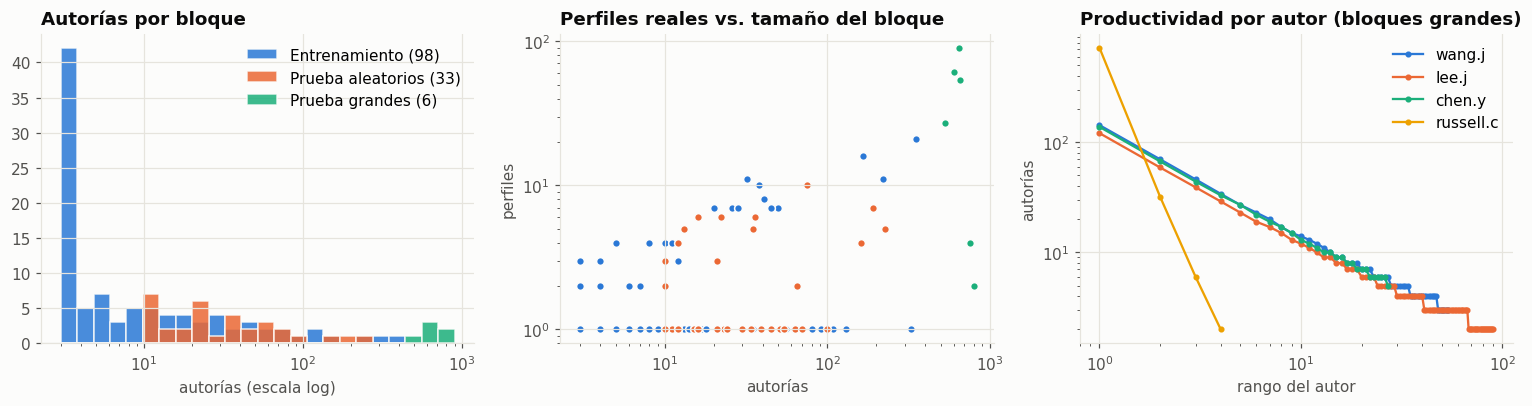

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
blk = df.groupby(["subset", "block"]).agg(n=("author_id", "size"), k=("author_id", "nunique")).reset_index()
lab = {"train": "Entrenamiento (98)", "test_random": "Prueba aleatorios (33)", "test_large": "Prueba grandes (6)"}
bins = np.logspace(np.log10(3), np.log10(900), 25)
for s, c in zip(lab, PL.PALETTE):
    axes[0].hist(blk[blk.subset == s].n, bins=bins, color=c, alpha=0.85, label=lab[s], edgecolor="#fcfcfb")
axes[0].set_xscale("log"); axes[0].set_title("Autorías por bloque"); axes[0].set_xlabel("autorías (escala log)")
axes[0].legend()
for s, c in zip(lab, PL.PALETTE):
    b = blk[blk.subset == s]
    axes[1].scatter(b.n, b.k, s=26, color=c, label=lab[s], edgecolor="#fcfcfb", linewidth=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Perfiles reales vs. tamaño del bloque"); axes[1].set_xlabel("autorías"); axes[1].set_ylabel("perfiles")
prod = df[df.subset == "test_large"].groupby(["block", "author_id"]).size()
for b, c in zip(["wang.j", "lee.j", "chen.y", "russell.c"], PL.PALETTE):
    v = np.sort(prod.loc[b].values)[::-1]
    axes[2].plot(np.arange(1, len(v) + 1), v, marker="o", ms=3, lw=1.5, color=c, label=b)
axes[2].set_xscale("log"); axes[2].set_yscale("log")
axes[2].set_title("Productividad por autor (bloques grandes)"); axes[2].set_xlabel("rango del autor"); axes[2].set_ylabel("autorías")
axes[2].legend()
fig.tight_layout(); PL.save(fig, "01_bloques_y_productividad.png")

Las variables de pares se calculan con `src/features.py` siguiendo la **Tabla 2** del artículo (nombre, afiliación, revista, año, título/resumen, palabras clave, coautores y bloque). ¿Cuáles separan las clases?

y,0,1
variable,,
firma compatible,0.748,0.994
nombre de pila igual,0.022,0.160
coautor en común,0.018,0.555
top-5 palabras en común,0.051,0.322
misma ciudad,0.009,0.380
ambas en revista top,0.281,0.165


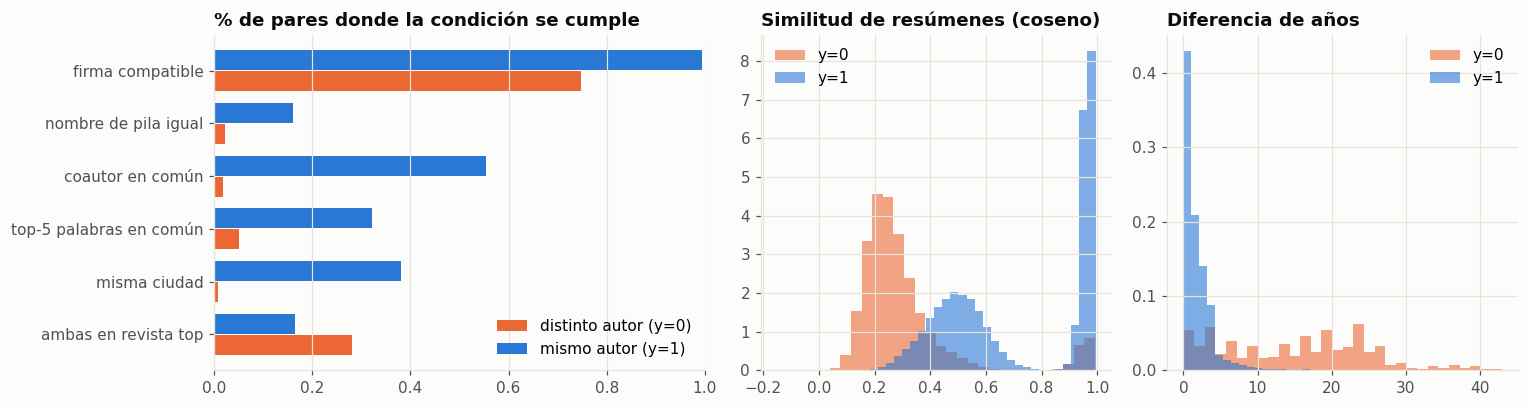

In [10]:
show = {"signature_compatible": "firma compatible", "first_name_equal": "nombre de pila igual",
        "coauthors_match": "coautor en común", "top_words_match": "top-5 palabras en común",
        "city_match": "misma ciudad", "journal_top": "ambas en revista top"}
tr = pairs[pairs.subset == "train"]
rows = []
for f, name in show.items():
    for y in (0, 1):
        v = tr.loc[tr.y == y, f]
        rows.append({"variable": name, "y": y, "valor": (v == 1).mean()})
share = pd.DataFrame(rows).pivot(index="variable", columns="y", values="valor").loc[list(show.values())]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.4, 1, 1]})
yy = np.arange(len(share))
axes[0].barh(yy + 0.2, share[0], 0.38, color=PL.PALETTE[1], label="distinto autor (y=0)")
axes[0].barh(yy - 0.2, share[1], 0.38, color=PL.PALETTE[0], label="mismo autor (y=1)")
axes[0].set_yticks(yy, share.index); axes[0].invert_yaxis(); axes[0].set_xlim(0, 1)
axes[0].set_title("% de pares donde la condición se cumple"); axes[0].legend(loc="lower right")
axes[0].grid(axis="y", visible=False)
for ax, f, t in [(axes[1], "abstract_sim", "Similitud de resúmenes (coseno)"), (axes[2], "year_diff", "Diferencia de años")]:
    for y, c in ((0, PL.PALETTE[1]), (1, PL.PALETTE[0])):
        v = tr.loc[(tr.y == y) & (tr[f] > -1), f]
        ax.hist(v, bins=30, density=True, alpha=0.6, color=c, label=f"y={y}")
    ax.set_title(t); ax.legend()
fig.tight_layout(); PL.save(fig, "01_variables_por_clase.png")
share.round(3)

**Lectura:**
* La compatibilidad de firma está presente en casi todos los pares del mismo autor, pero también en la mayoría de pares de autores distintos: **el nombre solo no basta**, que es justamente la motivación del artículo.
* Coautores, temas (palabras, resumen), ciudad y la cercanía en años separan mucho mejor las clases.
* Las variables de revista son débiles: casi todo el mundo publica en las revistas top.

Los pares quedan en caché en `data/processed/` (no se versionan; se regeneran en ~30 s).